# 01 · Auditoría de datos y exploración

Este cuaderno revisa la calidad del archivo antes de modelar. El objetivo no es asumir que cada fila del CSV representa evidencia independiente, sino documentar la estructura real del dataset y construir una base limpia y reproducible.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


In [2]:
from src.data import load_raw_data, audit_data, clean_data, descriptive_summary

raw = load_raw_data()
raw.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0000,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1000,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6000,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0000,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9000,1,3,2,0


## Estructura inicial

El dataset incluye 13 predictores y `target` como variable binaria. Aunque todas las columnas están almacenadas numéricamente, varias representan categorías codificadas; esa distinción se respetará en el modelo.

In [3]:
audit = audit_data(raw)
display(audit)
print(f"Shape original: {raw.shape}")
print(f"Duplicados exactos: {raw.duplicated().sum():,}")
print(f"Celdas faltantes: {raw.isna().sum().sum():,}")

,metric,value
0,rows_raw,1025
1,columns,14
2,missing_cells,0
3,exact_duplicate_rows,723
4,target_0,499
5,target_1,526


Shape original: (1025, 14)
Duplicados exactos: 723
Celdas faltantes: 0


## Duplicados exactos

La auditoría revela una cantidad inusualmente alta de filas repetidas. Para un análisis inferencial, tratarlas como observaciones independientes inflaría artificialmente el tamaño muestral. La versión de trabajo elimina únicamente duplicados exactos y no aplica imputaciones ni filtros adicionales.

In [4]:
clean, cleaning_audit = clean_data(raw)
display(cleaning_audit)
print(f"Shape limpio: {clean.shape}")

,metric,value
0,rows_before_deduplication,1025
1,rows_after_deduplication,302
2,duplicates_removed,723
3,missing_cells_after_cleaning,0
4,target_0_after_cleaning,138
5,target_1_after_cleaning,164


Shape limpio: (302, 14)


,count
target,
0,138
1,164


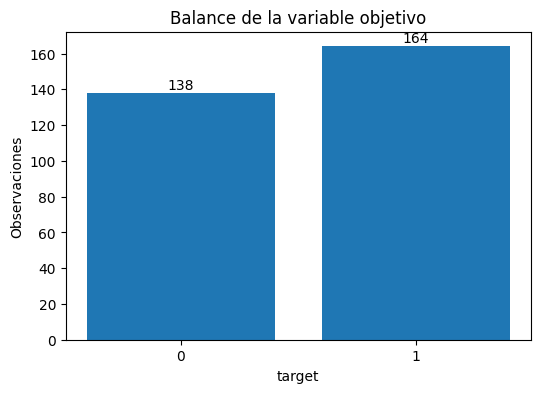

In [5]:
target_counts = clean["target"].value_counts().sort_index()
display(target_counts.rename("count").to_frame())

fig, ax = plt.subplots(figsize=(6,4))
ax.bar(target_counts.index.astype(str), target_counts.values)
ax.set_title("Balance de la variable objetivo")
ax.set_xlabel("target")
ax.set_ylabel("Observaciones")
for i, v in enumerate(target_counts.values):
    ax.text(i, v + 2, str(v), ha="center")
plt.show()

## Resumen descriptivo

La tabla siguiente es descriptiva; todavía no implica causalidad ni significancia estadística.

In [6]:
summary = descriptive_summary(clean)
display(summary)

,count,mean,std,min,25%,50%,75%,max,missing,unique
age,302.0000,54.4205,9.0480,29.0000,48.0000,55.5000,61.0000,77.0000,0,41
sex,302.0000,0.6821,0.4664,0.0000,0.0000,1.0000,1.0000,1.0000,0,2
cp,302.0000,0.9636,1.0320,0.0000,0.0000,1.0000,2.0000,3.0000,0,4
trestbps,302.0000,131.6026,17.5634,94.0000,120.0000,130.0000,140.0000,200.0000,0,49
chol,302.0000,246.5000,51.7535,126.0000,211.0000,240.5000,274.7500,564.0000,0,152
fbs,302.0000,0.1490,0.3567,0.0000,0.0000,0.0000,0.0000,1.0000,0,2
restecg,302.0000,0.5265,0.5260,0.0000,0.0000,1.0000,1.0000,2.0000,0,3
thalach,302.0000,149.5695,22.9035,71.0000,133.2500,152.5000,166.0000,202.0000,0,91
exang,302.0000,0.3278,0.4702,0.0000,0.0000,0.0000,1.0000,1.0000,0,2
oldpeak,302.0000,1.0430,1.1615,0.0000,0.0000,0.8000,1.6000,6.2000,0,40


## Variables cuantitativas seleccionadas

Para una primera lectura visual se revisan correlaciones entre variables con interpretación cuantitativa directa. Las variables categóricas codificadas se analizarán mediante indicadores en la regresión logística, no mediante correlaciones lineales sobre sus códigos.

,age,trestbps,chol,thalach,oldpeak,ca,target
age,1.0000,0.2831,0.2072,-0.3952,0.2060,0.3023,-0.2215
trestbps,0.2831,1.0000,0.1253,-0.0480,0.1946,0.0992,-0.1463
chol,0.2072,0.1253,1.0000,-0.0053,0.0501,0.0869,-0.0814
thalach,-0.3952,-0.0480,-0.0053,1.0000,-0.3422,-0.2283,0.4200
oldpeak,0.2060,0.1946,0.0501,-0.3422,1.0000,0.2366,-0.4291
ca,0.3023,0.0992,0.0869,-0.2283,0.2366,1.0000,-0.4090
target,-0.2215,-0.1463,-0.0814,0.4200,-0.4291,-0.4090,1.0000


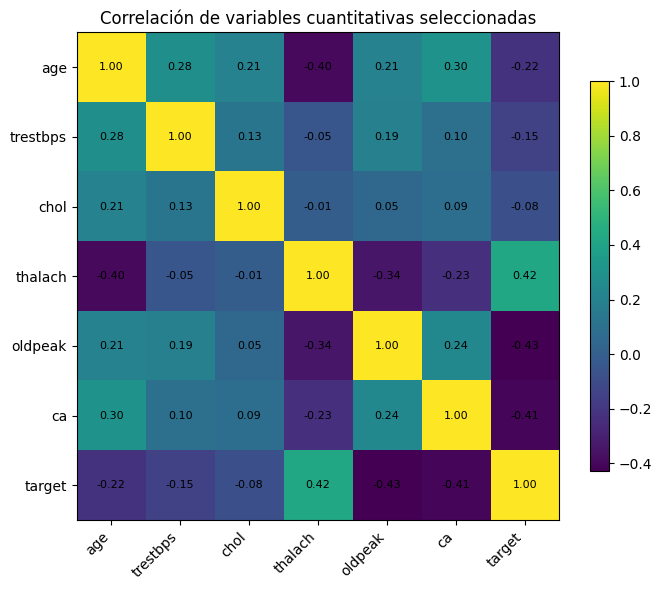

In [7]:
continuous = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca", "target"]
corr = clean[continuous].corr()
display(corr)

fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(corr, aspect="auto")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=.8)
ax.set_title("Correlación de variables cuantitativas seleccionadas")
plt.tight_layout()
plt.show()

## Conclusión de auditoría

La principal decisión de calidad es trabajar con **302 observaciones únicas** en lugar de las 1,025 filas originales. No hay valores faltantes. El balance de `target` es suficientemente cercano entre clases para continuar con regresión logística sin reponderación de clases en el análisis inferencial.